In [58]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PatchCollection, PathCollection
from matplotlib.patches import Circle, Polygon, RegularPolygon
from matplotlib.path import Path

## 8x8 lattice mapping to Heron r2

In [21]:
sqrt3o2 = np.sqrt(3.) * 0.5
oneotwos3 = 0.5 / np.sqrt(3.)

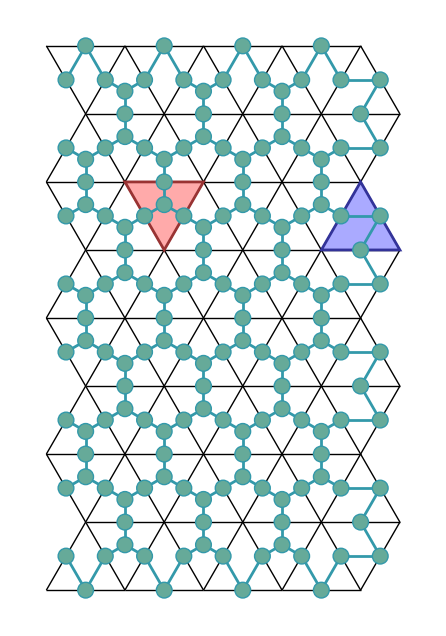

In [22]:
radius = 0.1

edges = []
qubits = []

for irow in range(9):
    y = irow * sqrt3o2
    x = (irow % 2) * 0.5
    for _ in range(4):
        edges.append([(x, y), (x + 1., y)])
        qubits.append(Circle((x + 0.5, y), radius))
        x += 1.

for irow in range(0, 8, 2):
    y = irow * sqrt3o2
    x = 0.
    for icol in range(4):
        edges.append([(x, y), (x + 0.5, y + sqrt3o2)])
        edges.append([(x + 0.5, y + sqrt3o2), (x + 1., y)])
        qubits.append(Circle((x + 0.25, y + sqrt3o2 * 0.5), radius))
        qubits.append(Circle((x + 0.75, y + sqrt3o2 * 0.5), radius))
        if irow != 0:
            qubits.append(Circle((x + 0.5, y + oneotwos3), radius))
        if icol != 3:
            qubits.append(Circle((x + 1., y + oneotwos3 * 2.), radius))
        x += 1.
    edges.append([(x, y), (x + 0.5, y + sqrt3o2)])
    qubits.append(Circle((x + 0.25, y + sqrt3o2 * 0.5), radius))

for irow in range(1, 8, 2):
    y = irow * sqrt3o2
    x = 0.5
    for icol in range(4):
        edges.append([(x, y), (x - 0.5, y + sqrt3o2)])
        edges.append([(x, y), (x + 0.5, y + sqrt3o2)])
        qubits.append(Circle((x - 0.25, y + sqrt3o2 * 0.5), radius))
        qubits.append(Circle((x + 0.25, y + sqrt3o2 * 0.5), radius))
        if irow != 7:
            qubits.append(Circle((x, y + oneotwos3 * 2.), radius))
        if icol != 3:
            qubits.append(Circle((x + 0.5, y + oneotwos3), radius))
        x += 1.
    edges.append([(x, y), (x - 0.5, y + sqrt3o2)])
    qubits.append(Circle((x - 0.25, y + sqrt3o2 * 0.5), radius))

couplings = []
for irow in range(0, 8, 2):
    x = 0.5
    if irow == 0:
        y = 0.
        for icol in range(4):
            couplings.append([(x, y), (x - 0.25, y + sqrt3o2 * 0.5)])
            couplings.append([(x, y), (x + 0.25, y + sqrt3o2 * 0.5)])
            x += 1.
    else:
        y = irow * sqrt3o2 + oneotwos3
        for icol in range(4):
            couplings.append([(x, y), (x, y - oneotwos3)])
            couplings.append([(x, y), (x - 0.25, y - oneotwos3 + sqrt3o2 * 0.5)])
            couplings.append([(x, y), (x + 0.25, y - oneotwos3 + sqrt3o2 * 0.5)])
            x += 1.
    x = 1.
    y = irow * sqrt3o2 + oneotwos3 * 2.
    for icol in range(3):
        couplings.append([(x, y), (x, y + oneotwos3)])
        couplings.append([(x, y), (x - 0.25, y + oneotwos3 - sqrt3o2 * 0.5)])
        couplings.append([(x, y), (x + 0.25, y + oneotwos3 - sqrt3o2 * 0.5)])
        x += 1.
    x += 0.25
    y = (irow + 0.5) * sqrt3o2
    couplings.append([(x, y), (x - 0.5, y)])
    couplings.append([(x, y), (x - 0.25, y + sqrt3o2 * 0.5)])

for irow in range(1, 8, 2):
    x = 0.5
    if irow == 7:
        y = 8. * sqrt3o2
        for icol in range(4):
            couplings.append([(x, y), (x - 0.25, y - sqrt3o2 * 0.5)])
            couplings.append([(x, y), (x + 0.25, y - sqrt3o2 * 0.5)])
            x += 1.
    else:
        y = irow * sqrt3o2 + oneotwos3 * 2.
        for icol in range(4):
            couplings.append([(x, y), (x, y + oneotwos3)])
            couplings.append([(x, y), (x - 0.25, y + oneotwos3 - sqrt3o2 * 0.5)])
            couplings.append([(x, y), (x + 0.25, y + oneotwos3 - sqrt3o2 * 0.5)])
            x += 1.
    x = 1.
    y = irow * sqrt3o2 + oneotwos3
    for icol in range(3):
        couplings.append([(x, y), (x, y - oneotwos3)])
        couplings.append([(x, y), (x - 0.25, y - oneotwos3 + sqrt3o2 * 0.5)])
        couplings.append([(x, y), (x + 0.25, y - oneotwos3 + sqrt3o2 * 0.5)])
        x += 1.
    x += 0.25
    y = (irow + 0.5) * sqrt3o2
    couplings.append([(x, y), (x - 0.5, y)])
    couplings.append([(x, y), (x - 0.25, y - sqrt3o2 * 0.5)])

fig, ax = plt.subplots(figsize=(5.5, 8))
ax.add_collection(LineCollection(edges, zorder=1., color='k', linewidth=1.))
ax.add_collection(PatchCollection(qubits, zorder=2., facecolors='#66aa99', edgecolors='#3399aa'))
ax.add_collection(LineCollection(couplings, zorder=1.5, color='#3399aa', linewidth=2.))
ax.add_patch(
    Polygon([(1., 6. * sqrt3o2), (2., 6. * sqrt3o2), (1.5, 5. * sqrt3o2)],
            facecolor='#ffaaaa', edgecolor='#993333', linewidth=2.)
)
ax.add_patch(
    Polygon([(3.5, 5. * sqrt3o2), (4.5, 5. * sqrt3o2), (4., 6. * sqrt3o2)],
            facecolor='#aaaaff', edgecolor='#333399', linewidth=2.)
)
ax.axis('equal')
ax.set_axis_off()
fig.savefig('/data/iiyama/2dz2/plots/lattice.pdf')

## Link-plaquette correspondence

In [52]:
def twobyfive(with_charges=True, edge_color='k'):
    radius = 0.1
    edges = []

    for irow in range(3):
        y = irow * sqrt3o2
        x = (irow % 2) * 0.5
        for _ in range(3 - (irow % 2)):
            edges.append([(x, y), (x + 1., y)])
            x += 1.

    for irow in range(0, 2, 2):
        y = irow * sqrt3o2
        x = 0.
        for icol in range(3):
            edges.append([(x, y), (x + 0.5, y + sqrt3o2)])
            edges.append([(x + 0.5, y + sqrt3o2), (x + 1., y)])
            x += 1.

    for irow in range(1, 2, 2):
        y = irow * sqrt3o2
        x = 0.5
        for icol in range(3):
            edges.append([(x, y), (x - 0.5, y + sqrt3o2)])
            edges.append([(x, y), (x + 0.5, y + sqrt3o2)])
            x += 1.

    fig, ax = plt.subplots(figsize=(5., 5.))
    ax.axis('equal')
    ax.set_axis_off()
    
    ax.add_collection(LineCollection(edges, zorder=1., color=edge_color, linewidth=1.))

    if with_charges:
        charges = [
            Circle((0.5, sqrt3o2), radius),
            Circle((2.5, sqrt3o2), radius)
        ]
        ax.add_collection(PatchCollection(charges, zorder=2., facecolors="#9999ff", edgecolors='#6666aa'))

    return ax

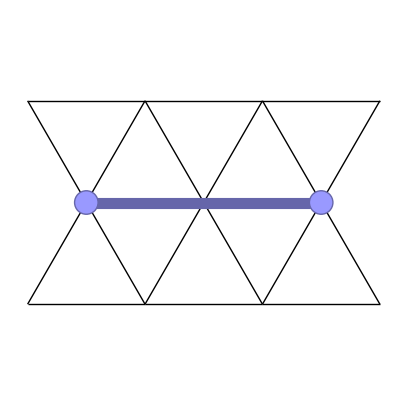

In [49]:
ax = twobyfive()

flux = [[(0.5, sqrt3o2), (2.5, sqrt3o2)]]
ax.add_collection(LineCollection(flux, zorder=1.5, color='#6666aa', linewidth=8.))

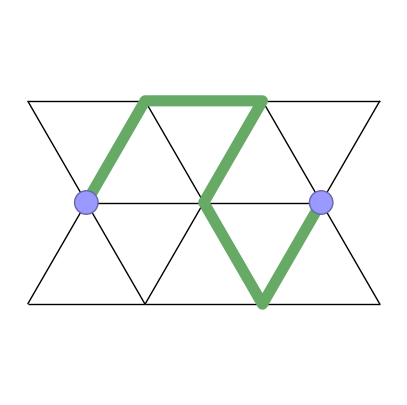

In [68]:
ax = twobyfive()

vertices = [
    (0.5, sqrt3o2),
    (1., 2. * sqrt3o2),
    (2., 2. * sqrt3o2),
    (1.5, sqrt3o2),
    (2., 0.),
    (2.5, sqrt3o2)
]
ax.add_collection(PathCollection([Path(vertices, closed=False)], zorder=1.5, color='#66aa66', facecolor='none', linewidth=8.))

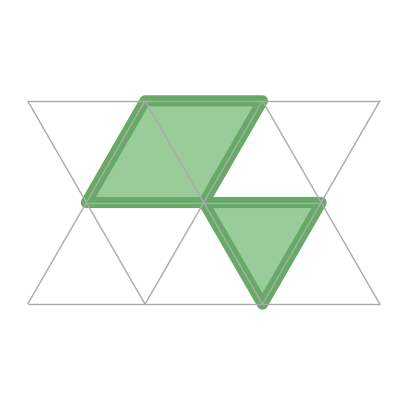

In [65]:
ax = twobyfive(with_charges=False, edge_color='#aaaaaa')

plaquettes = [
    RegularPolygon((1., sqrt3o2 + oneotwos3), 3, radius=oneotwos3 * 2.),
    RegularPolygon((1.5, sqrt3o2 + 2. * oneotwos3), 3, radius=oneotwos3 * 2., orientation=np.pi),
    RegularPolygon((2., 2. * oneotwos3), 3, radius=oneotwos3 * 2., orientation=np.pi)
]
ax.add_collection(PatchCollection(plaquettes, zorder=0.5, facecolors="#99cc99", linewidths=0.))

# borders = [
#     [(0.5, sqrt3o2), (1., 2. * sqrt3o2)],
#     [(1., 2. * sqrt3o2), (2., 2. * sqrt3o2)],
#     [(0.5, sqrt3o2), (1.5, sqrt3o2)],
#     [(2., 2. * sqrt3o2), (1.5, sqrt3o2)],
#     [(1.5, sqrt3o2), (2.5, sqrt3o2)],
#     [(1.5, sqrt3o2), (2., 0.)],
#     [(2., 0.), (2.5, sqrt3o2)]
# ]
# ax.add_collection(LineCollection(borders, zorder=2., color='#66aa66', linewidth=8.))
paths = [
    [(0.5, sqrt3o2), (1., 2. * sqrt3o2), (2., 2. * sqrt3o2), (1.5, sqrt3o2), (0.5, sqrt3o2)],
    [(1.5, sqrt3o2), (2., 0.), (2.5, sqrt3o2), (1.5, sqrt3o2)]
]
ax.add_collection(PathCollection([Path(vertices, closed=True) for vertices in paths], zorder=0.8, color='#66aa66', facecolor='none', linewidth=8.))